# Standalone EDA: Diabetes 130-US Hospitals

This notebook independently loads OpenML dataset 4541 and explores its structure, target, missingness, identifiers, class imbalance, and selected feature distributions. It does not import project `.py` files or use `config.yaml`. We used this notebook for our first look at the data, this format helps us better visualise and understand since we are used to the `.ipynb` format. This is supplementary working.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from IPython.display import display

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

## 1. Load the raw dataset

In [2]:
DATASET_ID = 4541
TARGET_COLUMN = 'readmitted'

X_raw, y_raw = fetch_openml(
    data_id=DATASET_ID,
    as_frame=True,
    return_X_y=True,
)

df = X_raw.copy()
df[TARGET_COLUMN] = y_raw

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
for col in df.columns:
    if str(df[col].dtype) == "category":
        df[col] = df[col].astype("object")

df = df.replace(["?", ""], np.nan)

display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Dataset structure and target

In [4]:
print('Number of rows:', df.shape[0])
print('Number of columns:', df.shape[1])
display(df.dtypes.astype(str).value_counts())
display(df.sample(5, random_state=42))

print('Original target counts:')
display(df[TARGET_COLUMN].value_counts(dropna=False))

df['early_readmission'] = (
    df[TARGET_COLUMN].astype(str).eq('<30').astype(int)
)

print('Binary target counts:')
display(df['early_readmission'].value_counts())
print('Binary target proportions (%):')
display(df['early_readmission'].value_counts(normalize=True).mul(100).round(2))

Number of rows: 101766
Number of columns: 50


object    37
int64     13
Name: count, dtype: int64

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed,readmitted
35956,110939484,19274094,Caucasian,Female,[70-80),NaN,1,1,6,11,UN,InternalMedicine,68,0,20,0,0,0,250.8,599,263,5,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO
60927,170328306,65634327,Caucasian,Male,[50-60),NaN,1,1,1,1,HM,NaN,20,0,7,0,0,0,780,427,E941,8,None,None,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
79920,245688426,100657359,Caucasian,Female,[60-70),NaN,3,6,1,4,HM,NaN,21,3,23,1,0,2,715,733,724,7,None,None,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
50078,150826224,83144448,Caucasian,Male,[30-40),NaN,2,1,1,12,CP,Gastroenterology,28,0,19,0,0,1,494,277,117,7,None,None,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
44080,135993852,65234214,AfricanAmerican,Female,[60-70),NaN,1,2,7,1,NaN,NaN,21,0,6,0,0,0,403,584,428,7,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,<30


Original target counts:


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Binary target counts:


early_readmission
0    90409
1    11357
Name: count, dtype: int64

Binary target proportions (%):


early_readmission
0    88.84
1    11.16
Name: proportion, dtype: float64

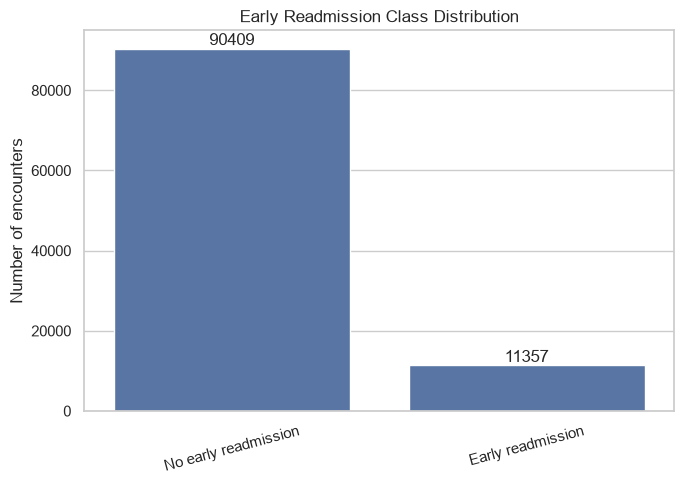

In [5]:
target_counts = df['early_readmission'].map({
    0: 'No early readmission',
    1: 'Early readmission',
}).value_counts()

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=target_counts.index, y=target_counts.values)
plt.title('Early Readmission Class Distribution')
plt.xlabel('')
plt.ylabel('Number of encounters')
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

## 3. Missingness analysis

,missing_count,missing_rate
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
encounter_id,0,0.00
tolazamide,0,0.00
glyburide,0,0.00


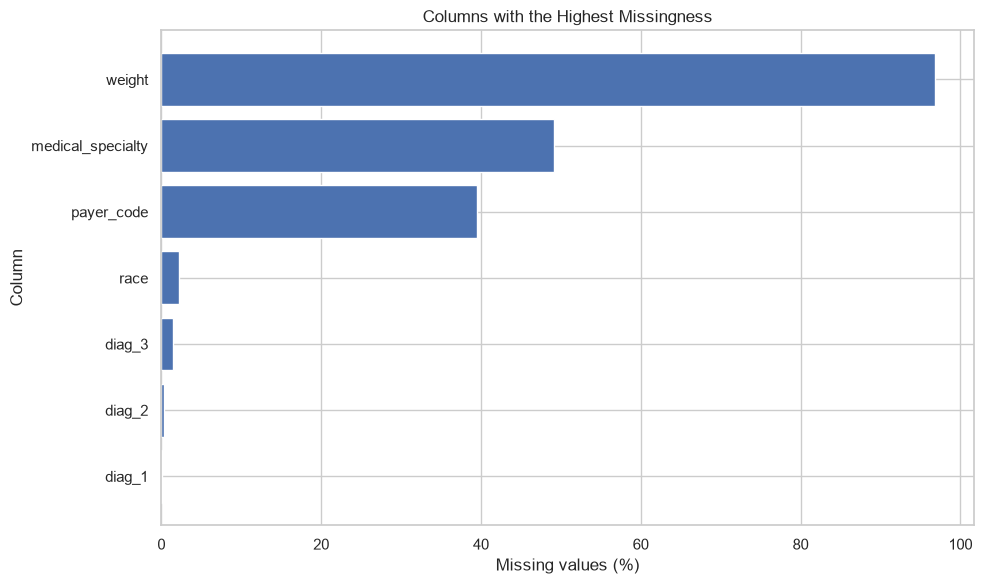

In [6]:
missingness = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_rate': df.isna().mean() * 100,
}).sort_values('missing_rate', ascending=False)

display(missingness.head(20).round(2))

missing_top = missingness.query('missing_rate > 0').head(15).sort_values('missing_rate')
plt.figure(figsize=(10, 6))
plt.barh(missing_top.index, missing_top['missing_rate'])
plt.xlabel('Missing values (%)')
plt.ylabel('Column')
plt.title('Columns with the Highest Missingness')
plt.tight_layout()
plt.show()

## 4. Candidate exclusions and identifiers

In [7]:
candidate_drop_columns = [
    'weight',
    'payer_code',
    'medical_specialty',
    'encounter_id',
    'patient_nbr',
]
candidate_drop_columns = [col for col in candidate_drop_columns if col in df.columns]

column_summary = pd.DataFrame({
    'dtype': df[candidate_drop_columns].dtypes.astype(str),
    'unique_values': [df[col].nunique(dropna=False) for col in candidate_drop_columns],
    'missing_rate': [df[col].isna().mean() * 100 for col in candidate_drop_columns],
})
display(column_summary.round(2))

identifier_columns = [col for col in ['encounter_id', 'patient_nbr'] if col in df.columns]
display(df[identifier_columns].head())

,dtype,unique_values,missing_rate
weight,object,10,96.86
payer_code,object,18,39.56
medical_specialty,object,73,49.08
encounter_id,int64,101766,0.00
patient_nbr,int64,71518,0.00


,encounter_id,patient_nbr
0,2278392,8222157
1,149190,55629189
2,64410,86047875
3,500364,82442376
4,16680,42519267


`encounter_id` and `patient_nbr` are identifiers rather than clinical predictors. `patient_nbr` can be retained temporarily for patient-level splitting, but it should be removed before model fitting.

In [8]:
patient_counts = (
    df.groupby("patient_nbr")
      .size()
      .rename("encounter_count")
      .sort_values(ascending=False)
)

print("Total unique patients:", patient_counts.shape[0])
print("Total encounters:", patient_counts.sum())
print("Patients with more than one encounter:", (patient_counts > 1).sum())
print("Maximum encounters for one patient:", patient_counts.max())

display(patient_counts.head(20))

Total unique patients: 71518
Total encounters: 101766
Patients with more than one encounter: 16773
Maximum encounters for one patient: 40


patient_nbr
88785891    40
43140906    28
1660293     23
23199021    23
88227540    23
23643405    22
84428613    22
92709351    21
23398488    20
29903877    20
90609804    20
37096866    20
88789707    20
89472402    20
88681950    19
88479036    19
97391007    19
3401055     18
91751121    18
84348792    18
Name: encounter_count, dtype: int64

In [9]:
repeat_summary = pd.Series({
    "unique_patients": patient_counts.size,
    "patients_with_1_encounter": (patient_counts == 1).sum(),
    "patients_with_multiple_encounters": (patient_counts > 1).sum(),
    "encounters_from_repeat_patients": patient_counts[patient_counts > 1].sum(),
    "percentage_of_patients_with_repeats": (patient_counts > 1).mean() * 100,
    "percentage_of_rows_from_repeat_patients": (
        patient_counts[patient_counts > 1].sum()
        / patient_counts.sum()
        * 100
    ),
})

display(repeat_summary.round(2))

unique_patients                            71518.00
patients_with_1_encounter                  54745.00
patients_with_multiple_encounters          16773.00
encounters_from_repeat_patients            47021.00
percentage_of_patients_with_repeats           23.45
percentage_of_rows_from_repeat_patients       46.21
dtype: float64

## 5. Race distribution and exploratory outcome rates

race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

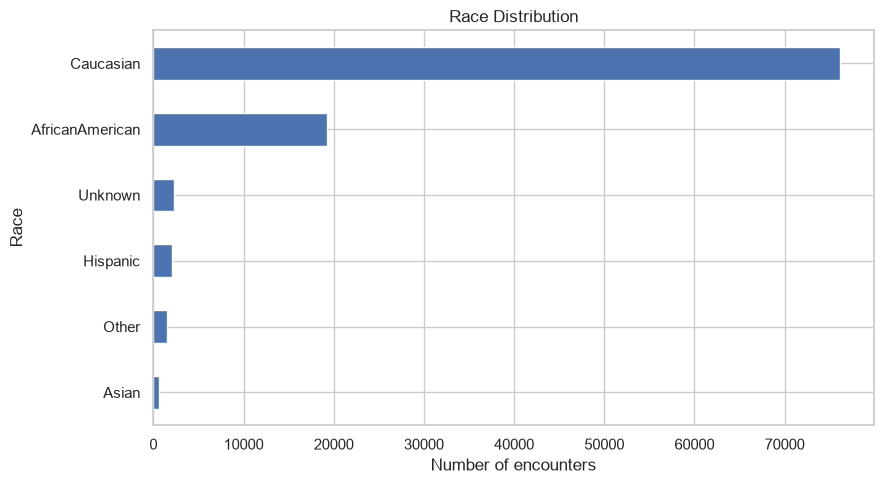

,count,mean,rate_percent
race,,,
AfricanAmerican,19210,0.112,11.218
Asian,641,0.101,10.140
Caucasian,76099,0.113,11.291
Hispanic,2037,0.104,10.407
Other,1506,0.096,9.628
Unknown,2273,0.083,8.271


In [10]:
race = df['race'].astype('object').fillna('Unknown')
race_counts = race.value_counts()
display(race_counts)

plt.figure(figsize=(9, 5))
race_counts.sort_values().plot(kind='barh')
plt.title('Race Distribution')
plt.xlabel('Number of encounters')
plt.ylabel('Race')
plt.tight_layout()
plt.show()

race_readmission = (
    pd.DataFrame({'race': race, 'early_readmission': df['early_readmission']})
    .groupby('race')['early_readmission']
    .agg(['count', 'mean'])
)
race_readmission['rate_percent'] = race_readmission['mean'] * 100
display(race_readmission.round(3))

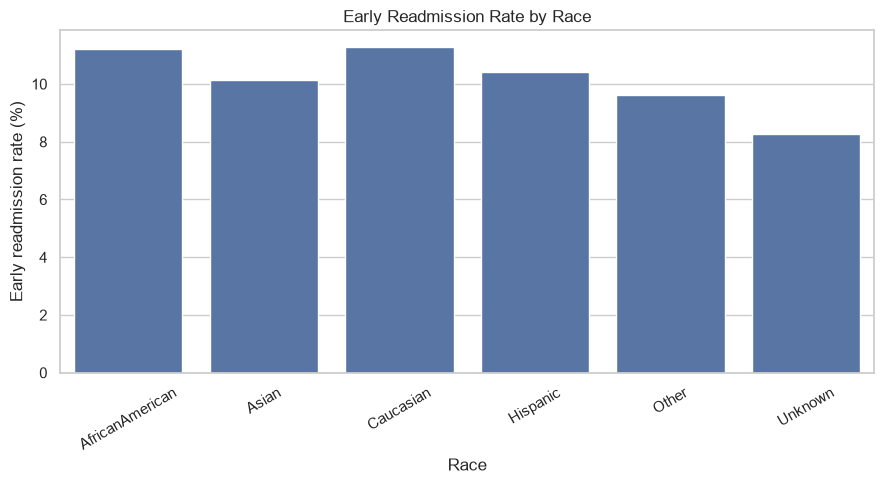

In [11]:
plt.figure(figsize=(9, 5))
sns.barplot(data=race_readmission.reset_index(), x='race', y='rate_percent')
plt.title('Early Readmission Rate by Race')
plt.xlabel('Race')
plt.ylabel('Early readmission rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. Numerical feature exploration

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,"101,766",4.40,2.99,1.00,2.00,4.00,6.00,14.00
num_lab_procedures,"101,766",43.10,19.67,1.00,31.00,44.00,57.00,132.00
num_procedures,"101,766",1.34,1.71,0.00,0.00,1.00,2.00,6.00
num_medications,"101,766",16.02,8.13,1.00,10.00,15.00,20.00,81.00
number_outpatient,"101,766",0.37,1.27,0.00,0.00,0.00,0.00,42.00
number_emergency,"101,766",0.20,0.93,0.00,0.00,0.00,0.00,76.00
number_inpatient,"101,766",0.64,1.26,0.00,0.00,0.00,1.00,21.00
number_diagnoses,"101,766",7.42,1.93,1.00,6.00,8.00,9.00,16.00


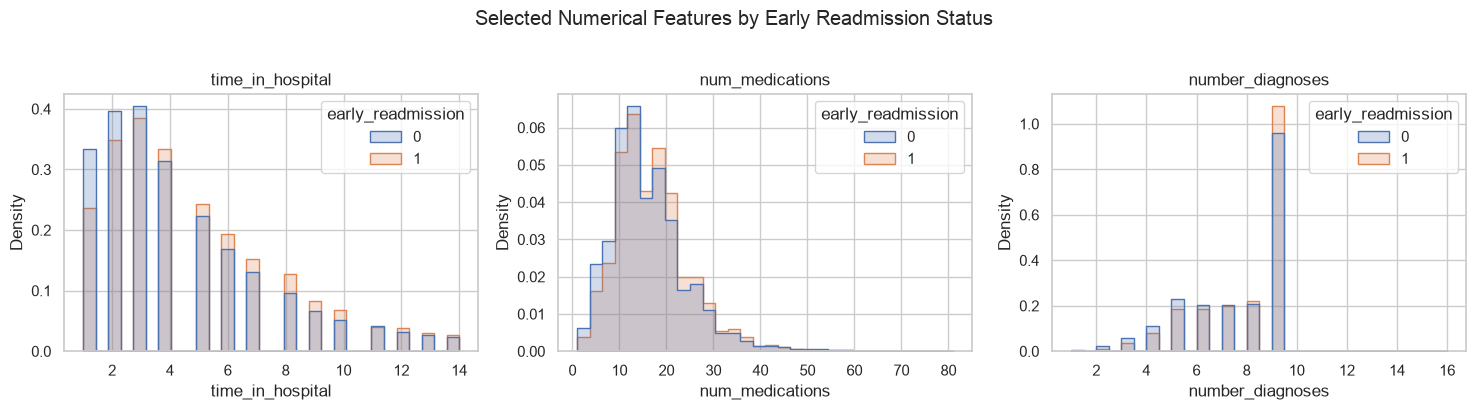

In [13]:
meaningful_numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

meaningful_numeric_columns = [
    col for col in meaningful_numeric_columns
    if col in df.columns
]

summary = df[meaningful_numeric_columns].describe().T

display(
    summary.style.format({
        "count": "{:,.0f}",
        "mean": "{:,.2f}",
        "std": "{:,.2f}",
        "min": "{:,.2f}",
        "25%": "{:,.2f}",
        "50%": "{:,.2f}",
        "75%": "{:,.2f}",
        "max": "{:,.2f}",
    })
)

selected_columns = [
    'time_in_hospital',
    'num_medications',
    'number_diagnoses'
]
selected_columns = [col for col in selected_columns if col in df.columns]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
for ax, column in zip(axes.flat, selected_columns):
    sns.histplot(data=df, x=column, hue='early_readmission', bins=30,
                 element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(column)
plt.suptitle('Selected Numerical Features by Early Readmission Status', y=1.02)
plt.tight_layout()
plt.show()

## EDA conclusions

This exploration documents the dataset size, binary target definition, class imbalance, missingness profile, identifier columns, race-group sizes, and selected feature distributions. These observations inform the later decisions to exclude highly incomplete variables, remove identifiers from modelling, handle class imbalance with class weighting, and audit performance across race groups.